# DE vs ALC: base rank (r=8) vs high rank (r=40, sweep dhp5wasn)

Restricted version of the "DE vs Curve" section in `analyse_qwen_only_new DS.ipynb` (cells 24-29): only DE and ALC (fixed/pretrained-control-point curve) are compared, no Linear/FLC free-curve baseline. Overlays the LoRA rank-40 rerun of the ALC sweep (`dhp5wasn`, still running) on top of the original rank-8 results, reusing the palette slots the original plot used for FLC since FLC isn't shown here.

### init

In [33]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = ""
os.environ["JAX_PLATFORMS"] = "cpu"

import wandb
from tqdm import tqdm
from copy import deepcopy
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

n_name = r"$N$"
free_model_name = "FLC"
pretrained_model_name = "ALC"

%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [34]:
def get_figsize(columnwidth, wf=0.5, hf=(5.**0.5-1.0)/2.0, ):
    """Parameters:
    - wf [float]:  width fraction in columnwidth units
    - hf [float]:  height fraction in columnwidth units.
                    Set by default to golden ratio.
    - columnwidth [float]: width of the column in latex. Get this from LaTeX
                            using \\showthe\\columnwidth
    Returns:  [fig_width,fig_height]: that should be given to matplotlib
    """
    fig_width_pt = columnwidth*wf
    inches_per_pt = 1.0/72.27               # Convert pt to inch
    fig_width = fig_width_pt*inches_per_pt  # width in inches
    fig_height = fig_width*hf      # height in inches
    return [fig_width, fig_height]


fig_width_pt = 397.48499  # Get this from LaTeX using \showthe\columnwidth
inches_per_pt = 1.0/72.27               # Convert pt to inches
golden_mean = (np.sqrt(5)-1.0)/2.0         # Aesthetic ratio
fig_width = fig_width_pt*inches_per_pt  # width in inches
fig_height = fig_width*golden_mean       # height in inches
figsize = [fig_width, fig_height]
print("Figure size=", figsize)
tex_fonts = {
    "text.usetex": True,
    "font.family": "Nimbus Sans",
    "axes.labelsize": 10,
    "font.size": 10,
    "legend.fontsize": 9,
    "legend.title_fontsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "figure.figsize": figsize
}
plt.rcParams.update(tex_fonts)

Figure size= [5.499999861629998, 3.399186852607058]


### Load sweep results (shared helper)

Same per-run field extraction as the `Collect all bezier segments data` section of `analyse_qwen_only_new DS.ipynb`: for every finished run we log its PPD row, and if it's a `Pretraining=True` (fixed control point) run we additionally log the DE row and the PPD-Uniform (BMA over the curve) row.

In [35]:
api = wandb.Api()


def collect_sweep_results(sweep_ids, project="qwen_PtoC_newDS", entity="ddold"):
    results = []
    for s in set(sweep_ids):
        t_run = tqdm(api.sweep(f"{entity}/{project}/{s}").runs)
        t_run.set_description(s)
        for run in t_run:
            if run.state != "finished":
                continue
            t_run.set_postfix_str(run.name)
            mp = run.config["model_params"]
            lora = mp["lora_params"]

            NCurveSegment = mp["num_curve_segment"]
            CurveDegree = mp["SegDeg"]
            res = dict(
                Id=run.id,
                CurveSpace=NCurveSegment * CurveDegree,
                NumPretrained=NCurveSegment + 1 if mp["Pretraining"] else 0,
                Jitter=mp["jitter_multiplier"],
                Seed=run.config["rng_seed"],
                WeightDecay=run.config["optimizer_conf"]["kwargs"]["weight_decay"],
                Dataset="_".join(run.config["data"]["dataset_path"].split("/")[-1].split(".")[0].split("_")[:-1]),
                BmaMode="PPD",
                LoraMode=lora.get("lora_mode", "None"),
                CurveMode=mp.get("curve_parameterization", "Bezier"),
                LoraRank=lora.get("r", -1),
                LoraRho=lora.get("lora_rho", -1),
                CurveSegmentDegree=CurveDegree,
                NCurveSegment=NCurveSegment,
                N=NCurveSegment + 1,
                M=CurveDegree - 1,
                N_cps=NCurveSegment * CurveDegree + 1,
                acc=run.summary.get("test_ppd_acc", -np.inf),
                ece=run.summary.get("test_ppd_ece", -np.inf),
                ll=run.summary.get("test_ppd_ll", -np.inf),
                brier=run.summary.get("test_ppd_brier", -np.inf),
                test_mean_entropy_ppd=run.summary.get("test_ppd_weighted_mean_entropy", -np.inf),
                test_mutual_information_ppd=run.summary.get("test_ppd_weighted_mutual_information", -np.inf),
                test_std_entropy_along_curve=0,
                test_mean_entropy_along_curve=0,
                SweepId=s,
            )
            results.append(res)

            if mp["Pretraining"]:
                _res = deepcopy(res)
                _res["BmaMode"] = "DE"
                _res["acc"] = run.summary.get("test_DE_acc", -np.inf)
                _res["ece"] = run.summary.get("test_DE_ece", -np.inf)
                _res["ll"] = run.summary.get("test_DE_ll", -np.inf)
                _res["brier"] = run.summary.get("test_DE_brier", -np.inf)
                _res["test_mean_entropy_ppd"] = run.summary.get("test_DE_uniform_mean_entropy", -np.inf)
                _res["test_mutual_information_ppd"] = run.summary.get("test_DE_uniform_mutual_information", -np.inf)
                _res["test_std_entropy_along_curve"] = run.summary.get("test_DE_uniform_std_entropy_along_curve", -np.inf)
                _res["test_mean_entropy_along_curve"] = run.summary.get("test_DE_uniform_mean_entropy_along_curve", -np.inf)
                results.append(_res)

            _res = deepcopy(res)
            _res["BmaMode"] = "PPD Uniform"
            _res["acc"] = run.summary.get("test_ppd_uniform_acc", -np.inf)
            _res["ece"] = run.summary.get("test_ppd_uniform_ece", -np.inf)
            _res["ll"] = run.summary.get("test_ppd_uniform_ll", -np.inf)
            _res["brier"] = run.summary.get("test_ppd_uniform_brier", -np.inf)
            _res["test_mean_entropy_ppd"] = run.summary.get("test_ppd_uniform_mean_entropy", -np.inf)
            _res["test_mutual_information_ppd"] = run.summary.get("test_ppd_uniform_mutual_information", -np.inf)
            _res["test_std_entropy_along_curve"] = run.summary.get("test_ppd_uniform_std_entropy_along_curve", -np.inf)
            _res["test_mean_entropy_along_curve"] = run.summary.get("test_ppd_uniform_mean_entropy_along_curve", -np.inf)
            results.append(_res)

    return pd.DataFrame(results)


def clean_df(df):
    cols = [col for col in df.columns if col[0].isupper()]
    idx_config_with_nan = df.isnull().values.any(axis=1)
    if idx_config_with_nan.any():
        print(f"Dropping {idx_config_with_nan.sum()} rows with missing config values")
    df_clean = df[~idx_config_with_nan].copy()
    idx_ids = [col for col in df.columns if col[0].isupper()]
    value_ids = np.setdiff1d(df.columns.values, idx_ids)
    return df_clean, idx_ids, value_ids

### Load base-rank (r=8) data — ALC/DE main sweep + boolq

In [36]:
# we8wq8n7: PretrainedFlat_Seg(1,2,4,8) (ALC), rank=8, all datasets except boolq
# kru2lo9d: PretrainedBoolq, rank=8, boolq only
df_base_raw = collect_sweep_results(["we8wq8n7", "kru2lo9d"])
df_clean_base, idx_ids, value_ids = clean_df(df_base_raw)
print(f"Base-rank (r=8): {len(df_clean_base)} rows, LoraRank={sorted(df_clean_base['LoraRank'].unique())}")
df_clean_base.head()

kru2lo9d: 100%|██████████| 40/40 [00:00<00:00, 160.31it/s, upbeat-sweep-1]    


Base-rank (r=8): 720 rows, LoraRank=[8]


,Id,CurveSpace,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,LoraMode,CurveMode,...,N_cps,acc,ece,ll,brier,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,SweepId
0,d5b1doju,24,9,0,8000,0.001,ARC-Easy,PPD,A(t)eB(t),bezier,...,25,0.968421,0.024970,-0.126809,0.055938,0.044838,0.001730,0.000000,0.000000,we8wq8n7
1,d5b1doju,24,9,0,8000,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,25,0.971930,0.015586,-0.098585,0.050350,0.085240,0.017494,0.020487,0.067746,we8wq8n7
2,d5b1doju,24,9,0,8000,0.001,ARC-Easy,PPD Uniform,A(t)eB(t),bezier,...,25,0.970175,0.011328,-0.096923,0.049216,0.090425,0.030278,0.016783,0.060147,we8wq8n7
3,ba9ox4nx,24,9,0,400,0.001,ARC-Easy,PPD,A(t)eB(t),bezier,...,25,0.961404,0.021769,-0.133842,0.057505,0.056460,0.000193,0.000000,0.000000,we8wq8n7
4,ba9ox4nx,24,9,0,400,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,25,0.971930,0.016524,-0.093314,0.047042,0.090964,0.016605,0.019183,0.074359,we8wq8n7


### Load high-rank (r=40) data — sweep `dhp5wasn`

This sweep is still running (partial results: as of writing, `winogrande_m` has full N/M coverage, `obqa` has a few N=2,M=1 runs, other datasets not started). Only the PPD-Uniform (curve BMA) rows are kept — we're overlaying the higher-rank *curve* result, not a second DE baseline.

In [37]:
df_highrank_raw = collect_sweep_results(["dhp5wasn"])
df_clean_highrank, _, _ = clean_df(df_highrank_raw)
df_clean_highrank = df_clean_highrank[df_clean_highrank["BmaMode"].isin(["DE", "PPD Uniform"])].copy()
print(f"High-rank (r=40): {len(df_clean_highrank)} rows, LoraRank={sorted(df_clean_highrank['LoraRank'].unique())}")
df_clean_highrank.head()

dhp5wasn: 100%|██████████| 187/187 [00:01<00:00, 173.95it/s, silvery-sweep-2]       


High-rank (r=40): 244 rows, LoraRank=[40]


,Id,CurveSpace,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,LoraMode,CurveMode,...,N_cps,acc,ece,ll,brier,test_mean_entropy_ppd,test_mutual_information_ppd,test_std_entropy_along_curve,test_mean_entropy_along_curve,SweepId
1,ws9hvo41,2,2,0,8000,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,3,0.961404,0.014194,-0.105098,0.055811,0.089543,0.009125,0.009493,0.080417,dhp5wasn
2,ws9hvo41,2,2,0,8000,0.001,ARC-Easy,PPD Uniform,A(t)eB(t),bezier,...,3,0.959649,0.020275,-0.107657,0.056972,0.075525,0.013577,0.016962,0.061948,dhp5wasn
4,cqunz8md,2,2,0,400,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,3,0.970175,0.020877,-0.103655,0.052007,0.067847,0.010255,0.017629,0.057592,dhp5wasn
5,cqunz8md,2,2,0,400,0.001,ARC-Easy,PPD Uniform,A(t)eB(t),bezier,...,3,0.970175,0.014936,-0.104142,0.051299,0.070777,0.009860,0.013613,0.060917,dhp5wasn
7,9zyr7spq,2,2,0,20,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,3,0.964912,0.016577,-0.115540,0.054293,0.060914,0.012653,0.003393,0.048261,dhp5wasn


### Build `Model` labels, filter, and merge into one plotting frame

In [38]:
LORA_RHO = 0.25

# --- base rank (r=8): DE + ALC ---
df_base = df_clean_base[
    (df_clean_base["LoraMode"] == "A(t)eB(t)")
    & (df_clean_base["LoraRho"] == LORA_RHO)
    & (df_clean_base["BmaMode"].isin(["DE", "PPD Uniform"]))
].copy()


def map_model_base(r):
    if r["BmaMode"] == "DE":
        return "DE"
    return f"{pretrained_model_name}(N,{r['M']})"


df_base["Model"] = df_base.apply(map_model_base, axis=1)

# --- high rank (r=40): DE + ALC, rank-subscripted labels ---
df_highrank = df_clean_highrank[
    (df_clean_highrank["LoraMode"] == "A(t)eB(t)")
    & (df_clean_highrank["LoraRho"] == LORA_RHO)
].copy()


def map_model_highrank(r):
    if r["BmaMode"] == "DE":
        return f"DE$_{{{int(r['LoraRank'])}}}$"
    return f"{pretrained_model_name}$_{{{int(r['LoraRank'])}}}$(N,{r['M']})"


df_highrank["Model"] = df_highrank.apply(map_model_highrank, axis=1)

df_plot_base = df_base.melt(id_vars=idx_ids + ["Model"], value_vars=value_ids, var_name="Metric", value_name="value")
df_plot_highrank = df_highrank.melt(id_vars=idx_ids + ["Model"], value_vars=value_ids, var_name="Metric", value_name="value")

df_plot = pd.concat([df_plot_base, df_plot_highrank], ignore_index=True)
df_plot["N"] = df_plot["N"].astype(str)
print(df_plot["Model"].unique())
df_plot.head()

['DE' 'ALC(N,2)' 'ALC(N,1)' 'DE$_{40}$' 'ALC$_{40}$(N,1)'
 'ALC$_{40}$(N,2)']


,Id,CurveSpace,NumPretrained,Jitter,Seed,WeightDecay,Dataset,BmaMode,LoraMode,CurveMode,...,LoraRho,CurveSegmentDegree,NCurveSegment,N,M,N_cps,SweepId,Model,Metric,value
0,d5b1doju,24,9,0,8000,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,we8wq8n7,DE,acc,0.971930
1,d5b1doju,24,9,0,8000,0.001,ARC-Easy,PPD Uniform,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,we8wq8n7,"ALC(N,2)",acc,0.970175
2,ba9ox4nx,24,9,0,400,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,we8wq8n7,DE,acc,0.971930
3,ba9ox4nx,24,9,0,400,0.001,ARC-Easy,PPD Uniform,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,we8wq8n7,"ALC(N,2)",acc,0.970175
4,0sttm8qr,24,9,0,20,0.001,ARC-Easy,DE,A(t)eB(t),bezier,...,0.25,3,8,9,2,25,we8wq8n7,DE,acc,0.970175


### Palette

Reuses the same `tab20c` indices as the original notebook's DE-vs-Curve plot for DE and ALC(N,1)/ALC(N,2), and reuses the indices that plot used for FLC(N,1)/FLC(N,2) for the rank-40 series, so the high-rank overlay renders in "the FLC color".

In [39]:
rank40 = int(df_highrank["LoraRank"].iloc[0]) if len(df_highrank) else 40

hue_order = [
    "DE",
    f"{pretrained_model_name}(N,1)",
    f"{pretrained_model_name}(N,2)",
    f"{pretrained_model_name}$_{{{rank40}}}$(N,1)",
    f"{pretrained_model_name}$_{{{rank40}}}$(N,2)",
]
_pal = sns.color_palette("tab20c")
hue_palette = {
    "DE": _pal[5],
    f"{pretrained_model_name}(N,1)": _pal[2],
    f"{pretrained_model_name}(N,2)": _pal[0],
    f"{pretrained_model_name}$_{{{rank40}}}$(N,1)": _pal[10],
    f"{pretrained_model_name}$_{{{rank40}}}$(N,2)": _pal[8],
}
hue_order = [m for m in hue_order if m in set(df_plot["Model"].unique())]
hue_palette = {k: v for k, v in hue_palette.items() if k in hue_order}
hue_order

['DE', 'ALC(N,1)', 'ALC(N,2)', 'ALC$_{40}$(N,1)', 'ALC$_{40}$(N,2)']

### Sanity check: how complete is the high-rank sweep so far?

In [40]:
df_plot[df_plot["Metric"] == "ll"].groupby(["Dataset", "N", "M", "Model"]).size().rename("n_runs")

Dataset        N  M  Model          
ARC-Challenge  2  1  ALC$_{40}$(N,1)    5
                     ALC(N,1)           5
                     DE                 5
                     DE$_{40}$          5
                  2  ALC$_{40}$(N,2)    5
                                       ..
winogrande_s   5  2  DE$_{40}$          5
               9  1  ALC(N,1)           5
                     DE                 5
                  2  ALC(N,2)           5
                     DE                 5
Name: n_runs, Length: 146, dtype: int64

### Plot: DE vs ALC, log-likelihood, base rank vs high rank

/tmp/ipykernel_1148415/929491133.py:8: UserWarning: 

The `join` parameter is deprecated and will be removed in v0.15.0. You can remove the line between points with `linestyle='none'`.

  g = sns.catplot(


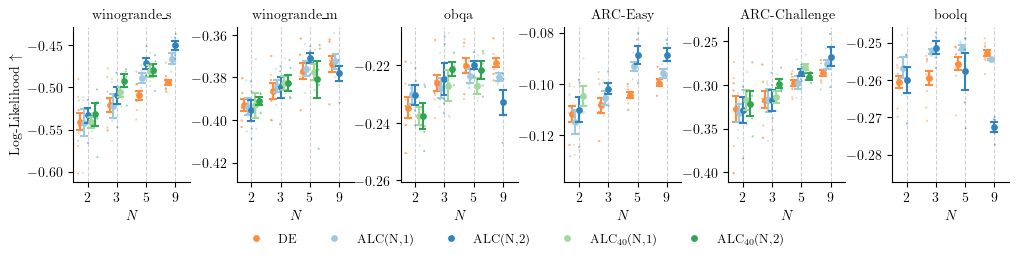

In [41]:
x_name = "N"
df_plot_ll = df_plot[df_plot["Metric"] == "ll"].copy()

full_ds_order = ["winogrande_s", "winogrande_m", "obqa", "ARC-Easy", "ARC-Challenge", "boolq"]
col_order_ds = [d for d in full_ds_order if d in df_plot_ll["Dataset"].unique()]
order = sorted(df_plot_ll[x_name].unique())

g = sns.catplot(
    data=df_plot_ll, y="value", x=x_name,
    col="Dataset", col_wrap=min(6, len(col_order_ds)),
    col_order=col_order_ds,
    order=order,
    kind="point", join=False, capsize=.2, linewidth=1.5,
    markers="o", palette=hue_palette, hue="Model",
    dodge=0.5, sharey=False, sharex=False, height=figsize[1]/1.4, aspect=1/1.4,
    legend=True, errorbar="se", hue_order=hue_order,
)

for ds, ax in g.axes_dict.items():
    subset = df_plot_ll[df_plot_ll["Dataset"] == ds]
    sns.stripplot(
        data=subset, y="value", x=x_name,
        order=order,
        ax=ax, palette=hue_palette, alpha=0.5, size=1.5,
        dodge=0.5, hue="Model", legend=False, hue_order=hue_order,
    )
    ax.grid(True, axis="x", linestyle="--", alpha=0.6)
    ax.set_ylabel("")

    def only_finite(x):
        return x[np.isfinite(x)]

    non_map_vals = only_finite(subset["value"])
    if not non_map_vals.empty:
        ax.set_ylim(bottom=non_map_vals.min() - 0.01)

g.axes[0].set_ylabel(r"Log-Likelihood $\uparrow$")
g.set_titles(col_template="{col_name}")
g.set_xlabels(n_name)
g.tight_layout()
g.fig.subplots_adjust(wspace=0.4)

sns.move_legend(g, loc="lower center", bbox_to_anchor=(0.45, -0.08), ncol=len(hue_order), title="")

os.makedirs("result", exist_ok=True)
plt.savefig("result/performance_DE_vs_ALC_rank_compare.pdf", dpi=300, bbox_inches="tight")
plt.show()

### Mean LL comparison per (Dataset, N): base rank vs high rank

Mean `ll` (averaged over curve-degree `M` and seeds) for each `(Dataset, N)` config, restricted to
`N in {2, 3, 5}` since that's the current coverage of the still-running high-rank sweep. Columns:
`ALC`/`DE` = base rank (r=8), `ALC_40`/`DE_40` = high rank (r=40, sweep `dhp5wasn`).

In [42]:
N_SUBSET = [2, 3, 5]

def _filtered(df, bmamode):
    return df[
        (df["LoraMode"] == "A(t)eB(t)")
        & (df["LoraRho"] == LORA_RHO)
        & (df["BmaMode"] == bmamode)
        & (df["Dataset"] != "boolq")
        & (df["N"].isin(N_SUBSET))
    ]


def _stat_ll(df, bmamode):
    g = _filtered(df, bmamode).groupby(["Dataset", "N", "M"])["ll"]
    stat = pd.concat([g.mean().rename("mean"), g.std().rename("std")], axis=1)

    def fmt(row):
        if pd.isna(row["mean"]):
            return np.nan
        if pd.isna(row["std"]):
            return f"{row['mean']:.3f}"
        return f"{row['mean']:.3f} ± {2 * row['std']:.3f}"

    return stat.apply(fmt, axis=1)


ll_table = pd.DataFrame({
    "ALC": _stat_ll(df_clean_base, "PPD Uniform"),
    "ALC_40": _stat_ll(df_clean_highrank, "PPD Uniform"),
    "DE": _stat_ll(df_clean_base, "DE"),
    "DE_40": _stat_ll(df_clean_highrank, "DE"),
}).reset_index()

ll_table = ll_table.sort_values(["Dataset", "N"]).reset_index(drop=True)
ll_table

,Dataset,N,M,ALC,ALC_40,DE,DE_40
0,ARC-Challenge,2,1,-0.332 ± 0.045,-0.317 ± 0.051,-0.325 ± 0.089,-0.324 ± 0.082
1,ARC-Challenge,2,2,-0.328 ± 0.066,-0.321 ± 0.063,-0.330 ± 0.107,-0.324 ± 0.082
2,ARC-Challenge,3,1,-0.318 ± 0.059,-0.314 ± 0.031,-0.314 ± 0.062,-0.309 ± 0.036
3,ARC-Challenge,3,2,-0.318 ± 0.054,-0.299 ± 0.023,-0.320 ± 0.069,-0.305 ± 0.061
4,ARC-Challenge,5,1,-0.298 ± 0.033,-0.279 ± 0.016,-0.298 ± 0.031,-0.289 ± 0.023
5,ARC-Challenge,5,2,-0.286 ± 0.017,-0.290 ± 0.013,-0.297 ± 0.016,-0.284 ± 0.023
6,ARC-Easy,2,1,-0.115 ± 0.021,-0.105 ± 0.017,-0.115 ± 0.022,-0.107 ± 0.018
7,ARC-Easy,2,2,-0.110 ± 0.022,NaN,-0.109 ± 0.018,NaN
8,ARC-Easy,3,1,-0.105 ± 0.012,NaN,-0.109 ± 0.019,NaN
9,ARC-Easy,3,2,-0.102 ± 0.010,NaN,-0.108 ± 0.019,NaN


In [44]:
### Per-dataset mean (ALC - ALC_40) log-likelihood gap
# `ll_table`'s ALC/ALC_40 columns are formatted strings ("-0.332 ± 0.045"), so subtract on the
# raw numeric means instead (same _filtered/N_SUBSET/groupby as _stat_ll, just without the fmt step).

def _mean_ll(df, bmamode):
    return _filtered(df, bmamode).groupby(["Dataset", "N", "M"])["ll"].mean()

ll_table_numeric = pd.DataFrame({
    "ALC": _mean_ll(df_clean_base, "PPD Uniform"),
    "ALC_40": _mean_ll(df_clean_highrank, "PPD Uniform"),
}).reset_index()

# ARC-Easy excluded: the high-rank (dhp5wasn) sweep hasn't run ARC-Easy yet, so ALC_40 is all-NaN there.
diff_per_dataset = (
    ll_table_numeric[ll_table_numeric["Dataset"] != "ARC-Easy"]
    .assign(ll_diff=lambda d: d["ALC"] - d["ALC_40"])
    .groupby("Dataset")["ll_diff"]
    .mean()
    .sort_values(key=np.abs, ascending=False)
)
diff_per_dataset

Dataset
ARC-Challenge   -0.009702
winogrande_s    -0.005871
obqa             0.002652
winogrande_m     0.000569
Name: ll_diff, dtype: float64

In [ ]:
# make markdown table for latex
ll_table.to_markdown()

'|    | Dataset       |   N |   M | ALC            | ALC_40         | DE             | DE_40          |\n|---:|:--------------|----:|----:|:---------------|:---------------|:---------------|:---------------|\n|  0 | ARC-Challenge |   2 |   1 | -0.332 ± 0.045 | -0.317 ± 0.051 | -0.325 ± 0.089 | -0.324 ± 0.082 |\n|  1 | ARC-Challenge |   2 |   2 | -0.328 ± 0.066 | -0.321 ± 0.063 | -0.330 ± 0.107 | -0.324 ± 0.082 |\n|  2 | ARC-Challenge |   3 |   1 | -0.318 ± 0.059 | -0.314 ± 0.031 | -0.314 ± 0.062 | -0.309 ± 0.036 |\n|  3 | ARC-Challenge |   3 |   2 | -0.318 ± 0.054 | -0.299 ± 0.023 | -0.320 ± 0.069 | -0.305 ± 0.061 |\n|  4 | ARC-Challenge |   5 |   1 | -0.298 ± 0.033 | -0.279 ± 0.016 | -0.298 ± 0.031 | -0.289 ± 0.023 |\n|  5 | ARC-Challenge |   5 |   2 | -0.286 ± 0.017 | -0.290 ± 0.013 | -0.297 ± 0.016 | -0.284 ± 0.023 |\n|  6 | ARC-Easy      |   2 |   1 | -0.115 ± 0.021 | -0.104 ± 0.020 | -0.115 ± 0.022 | -0.107 ± 0.020 |\n|  7 | ARC-Easy      |   2 |   2 | -0.110 ± 0.022 | nan        

In [ ]:
ll_table[ll_table['Dataset'] == 'winogrande_s'].to_markdown()

'|    | Dataset      |   N |   M | ALC            | ALC_40         | DE             | DE_40          |\n|---:|:-------------|----:|----:|:---------------|:---------------|:---------------|:---------------|\n| 24 | winogrande_s |   2 |   1 | -0.542 ± 0.073 | -0.542 ± 0.028 | -0.537 ± 0.061 | -0.525 ± 0.029 |\n| 25 | winogrande_s |   2 |   2 | -0.533 ± 0.039 | -0.532 ± 0.062 | -0.544 ± 0.077 | -0.530 ± 0.021 |\n| 26 | winogrande_s |   3 |   1 | -0.522 ± 0.062 | -0.505 ± 0.029 | -0.524 ± 0.060 | -0.513 ± 0.029 |\n| 27 | winogrande_s |   3 |   2 | -0.510 ± 0.047 | -0.492 ± 0.035 | -0.517 ± 0.048 | -0.511 ± 0.029 |\n| 28 | winogrande_s |   5 |   1 | -0.489 ± 0.027 | -0.480 ± 0.032 | -0.503 ± 0.029 | -0.500 ± 0.029 |\n| 29 | winogrande_s |   5 |   2 | -0.471 ± 0.030 | -0.479 ± 0.032 | -0.515 ± 0.037 | -0.506 ± 0.020 |'

### Dataset with the strongest ALC vs ALC_40 gap

Pick the dataset with the largest `|mean(ALC - ALC_40)|` from `diff_per_dataset` above (ARC-Easy already excluded there since its high-rank runs aren't finished), then print the full `ll_table` slice for that dataset as markdown.</cell id="4720b2a2">

In [45]:
selected_dataset = diff_per_dataset.index[0]
print(f"Strongest ALC vs ALC_40 mean LL gap: {selected_dataset} ({diff_per_dataset.iloc[0]:+.3f})")
selected_dataset

Strongest ALC vs ALC_40 mean LL gap: ARC-Challenge (-0.010)


'ARC-Challenge'

In [46]:
ll_table[ll_table['Dataset'] == selected_dataset].to_markdown()

'|    | Dataset       |   N |   M | ALC            | ALC_40         | DE             | DE_40          |\n|---:|:--------------|----:|----:|:---------------|:---------------|:---------------|:---------------|\n|  0 | ARC-Challenge |   2 |   1 | -0.332 ± 0.045 | -0.317 ± 0.051 | -0.325 ± 0.089 | -0.324 ± 0.082 |\n|  1 | ARC-Challenge |   2 |   2 | -0.328 ± 0.066 | -0.321 ± 0.063 | -0.330 ± 0.107 | -0.324 ± 0.082 |\n|  2 | ARC-Challenge |   3 |   1 | -0.318 ± 0.059 | -0.314 ± 0.031 | -0.314 ± 0.062 | -0.309 ± 0.036 |\n|  3 | ARC-Challenge |   3 |   2 | -0.318 ± 0.054 | -0.299 ± 0.023 | -0.320 ± 0.069 | -0.305 ± 0.061 |\n|  4 | ARC-Challenge |   5 |   1 | -0.298 ± 0.033 | -0.279 ± 0.016 | -0.298 ± 0.031 | -0.289 ± 0.023 |\n|  5 | ARC-Challenge |   5 |   2 | -0.286 ± 0.017 | -0.290 ± 0.013 | -0.297 ± 0.016 | -0.284 ± 0.023 |'